In [1]:
# Import libraries
import os
os.chdir("D:\\DESKTOP\\Current-Projects\\tbrucei_docking_data\\ML-steps\\Random-Split-ML\\negative-mammalian")
os.listdir()

['negative_mamalian.txt',
 'negative_rdkit_descriptors.csv',
 'scaffold_rdkit.csv',
 'tb-ml-random-CV-Features.ipynb.ipynb']

In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.impute import SimpleImputer

from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

In [5]:
# Load Dataset and prepare it
tb_neg = pd.read_csv("negative_rdkit_descriptors.csv", header=0)
print('shape of tb_neg: ', tb_neg.shape)
neg_deltaG = pd.read_csv("negative_mamalian.txt", header=0, sep=rf'\s+')
print('shape of neg_deltaG: ', neg_deltaG.shape)
scaffold_rdkit = pd.read_csv('scaffold_rdkit.csv', header=0, sep=',')
print('shape of scaffold_rdkit: ', scaffold_rdkit.shape)

shape of tb_neg:  (5882, 218)
shape of neg_deltaG:  (5882, 2)
shape of scaffold_rdkit:  (12966, 2)


In [7]:
print('#' * 80)
print("Top 10 rows of nb_pos")
print(tb_neg.head(10))
print('#' * 80)
print('Top 10 rows of neg_deltaG')
print(neg_deltaG.head(10))
print('#' * 80)
print('Top 10 rows of scaffold_rdkit')
print(scaffold_rdkit.head(10))

################################################################################
Top 10 rows of nb_pos
                Molecule  MaxAbsEStateIndex  MaxEStateIndex  \
0  ZINC000000071611.mol2          11.944844       11.944844   
1  ZINC000000073537.mol2          12.036924       12.036924   
2  ZINC000000117001.mol2          12.206000       12.206000   
3  ZINC000000128071.mol2          12.545301       12.545301   
4  ZINC000000160012.mol2           8.767243        8.767243   
5  ZINC000000267075.mol2          12.708503       12.708503   
6  ZINC000000317923.mol2          12.426558       12.426558   
7  ZINC000000456707.mol2          10.978941       10.978941   
8  ZINC000000489120.mol2           9.615715        9.615715   
9  ZINC000000538108.mol2          12.681459       12.681459   

   MinAbsEStateIndex  MinEStateIndex       qed        SPS    MolWt  \
0           0.384910       -0.536758  0.877366  19.636364  300.322   
1           0.403507       -0.496772  0.887926  19.541667  338.

In [8]:
# Remove '.mol2' suffix from column 'Molecule' in data frame tb_pos &tb_neg
tb_neg['Molecule'] = tb_neg['Molecule'].str.removesuffix('.mol2')
# Merging two data frames based on a column value
df_neg = pd.merge(tb_neg, neg_deltaG, on='Molecule', how='inner')
# Print TOP 10 rows of each data frame
print(df_neg.head())
print('#' * 80)

           Molecule  MaxAbsEStateIndex  MaxEStateIndex  MinAbsEStateIndex  \
0  ZINC000000071611          11.944844       11.944844           0.384910   
1  ZINC000000073537          12.036924       12.036924           0.403507   
2  ZINC000000117001          12.206000       12.206000           0.003482   
3  ZINC000000128071          12.545301       12.545301           0.329786   
4  ZINC000000160012           8.767243        8.767243           0.195473   

   MinEStateIndex       qed        SPS    MolWt  HeavyAtomMolWt  ExactMolWt  \
0       -0.536758  0.877366  19.636364  300.322         284.194  300.133474   
1       -0.496772  0.887926  19.541667  338.396         324.284  338.094980   
2       -0.838796  0.774549  16.333333  330.296         316.184  330.085186   
3       -0.329786  0.682747  13.545455  307.334         298.262  307.041548   
4        0.195473  0.728146  10.473684  285.357         278.301  285.014287   

   ...  fr_sulfonamd  fr_sulfone  fr_term_acetylene  fr_tetraz

In [9]:
print('Before combining, shapes of data frames: ', df_neg.shape)
print('Shape of scaffold_rdkit: ', scaffold_rdkit.shape)
df_tb_scaffold = pd.merge(df_neg, scaffold_rdkit, on='Molecule', how='inner')
print('Shape of df_tb_scaffold: ', df_tb_scaffold.shape)
# Remove 'Molecule' column from the data frame
new_df_tb_scaffold = df_tb_scaffold.drop(columns='Molecule')
print('Shpae of new_df_tb_scaffold: ', new_df_tb_scaffold.shape)

Before combining, shapes of data frames:  (5882, 219)
Shape of scaffold_rdkit:  (12966, 2)
Shape of df_tb_scaffold:  (5882, 220)
Shpae of new_df_tb_scaffold:  (5882, 219)


In [10]:
# Checking missing values from each feature
print('Checking missing values: ', new_df_tb_scaffold.isnull().sum()[new_df_tb_scaffold.isnull().sum() > 0])
print('Checking missing values in scaffold_rdkit: ', scaffold_rdkit.isnull().sum()[scaffold_rdkit.isnull().sum() > 0])
# print the list of missing values rows
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Checking missing values:  Scaffold    1
dtype: int64
Checking missing values in scaffold_rdkit:  Scaffold    41
dtype: int64


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold
5239,12.656052,12.656052,0.232689,-1.55818,0.113539,15.088235,488.542,452.254,488.259462,194,...,0,0,0,0,0,0,1,0,-1.6,NaN


In [11]:
# Delete missing values
new_df_tb_scaffold.dropna(inplace=True)
print('Shape of data frame after removing nulll values: ', new_df_tb_scaffold.shape)
# Check to list the missing values after deletion
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Shape of data frame after removing nulll values:  (5881, 219)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold


In [12]:
# Checking column data types of df_tb
for col in new_df_tb_scaffold.columns:
    print(col, new_df_tb_scaffold[col].dtype)

MaxAbsEStateIndex float64
MaxEStateIndex float64
MinAbsEStateIndex float64
MinEStateIndex float64
qed float64
SPS float64
MolWt float64
HeavyAtomMolWt float64
ExactMolWt float64
NumValenceElectrons int64
NumRadicalElectrons int64
MaxPartialCharge float64
MinPartialCharge float64
MaxAbsPartialCharge float64
MinAbsPartialCharge float64
FpDensityMorgan1 float64
FpDensityMorgan2 float64
FpDensityMorgan3 float64
BCUT2D_MWHI float64
BCUT2D_MWLOW float64
BCUT2D_CHGHI float64
BCUT2D_CHGLO float64
BCUT2D_LOGPHI float64
BCUT2D_LOGPLOW float64
BCUT2D_MRHI float64
BCUT2D_MRLOW float64
AvgIpc float64
BalabanJ float64
BertzCT float64
Chi0 float64
Chi0n float64
Chi0v float64
Chi1 float64
Chi1n float64
Chi1v float64
Chi2n float64
Chi2v float64
Chi3n float64
Chi3v float64
Chi4n float64
Chi4v float64
HallKierAlpha float64
Ipc float64
Kappa1 float64
Kappa2 float64
Kappa3 float64
LabuteASA float64
PEOE_VSA1 float64
PEOE_VSA10 float64
PEOE_VSA11 float64
PEOE_VSA12 float64
PEOE_VSA13 float64
PEOE_VSA14 floa

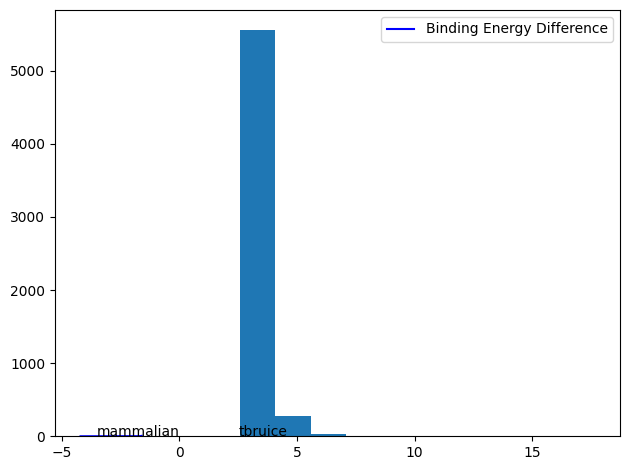

In [75]:
# distribution of 'BindingEnergyDiff' values
from scipy.stats import gaussian_kde

plt.figure()
def plot_values(data_frame):
    values = data_frame['BindingEnergyDiff'].dropna().values
    kde = gaussian_kde(values)
    x_vals = np.linspace(values.min(), values.max(), 1000)
    y_vals = kde(x_vals)
    return x_vals, y_vals

dx1, dy1 = plot_values(new_df_tb_scaffold)
BE = new_df_tb_scaffold["BindingEnergyDiff"]
plt.plot(dx1, dy1, color = 'blue', label='Binding Energy Difference')
plt.hist(BE**2)

plt.legend()
plt.text(-3.5, 0.4, 'mammalian')
plt.text(2.5, 0.4, 'tbruice')
plt.tight_layout()
plt.show()

In [14]:
# EXPLORATORY DATA ANALYSIS (EDA) 
# Finding relationship between features and remove constant value features, and \
# features containing correlation +1 or -1 values
columns_list = new_df_tb_scaffold.columns
uniq_value_columns = []
for col in columns_list:
    if new_df_tb_scaffold[col].nunique() == 1 :
        uniq_value_columns.append(col)

print('Uniq value columns: ', uniq_value_columns)
print('Total columns have unique value: ', len(uniq_value_columns))

# Remove uniq_value_columns from the data frame
print('Shape of data frame before deleting unique values: ', new_df_tb_scaffold.shape)
uniq_del_df_tb_scaffold = new_df_tb_scaffold.drop(columns=uniq_value_columns)
print('Shape of data frame after deleting unique values: ', uniq_del_df_tb_scaffold.shape)

# Calcualting data frame features correlation values for numeric features
# Calculate dimensions based on the number of features
num_features = len(uniq_del_df_tb_scaffold.select_dtypes(include=['number']).columns)
# Dynamically size the figure (e.g., 0.9 inches per feature)
plt.figure(figsize=(num_features * 0.9, num_features * 0.9))
sns.heatmap(uniq_del_df_tb_scaffold.corr(numeric_only=True), fmt=".2f", annot=True, cmap='coolwarm', vmin=-1, vmax=1)
# Remove limits on rows, columns, and width
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

uniq_del_df_tb_scaffold.corr(numeric_only=True).style.format("{: .2f}")


Uniq value columns:  ['NumRadicalElectrons', 'SMR_VSA8', 'SlogP_VSA9', 'NumAtomStereoCenters', 'NumUnspecifiedAtomStereoCenters', 'fr_benzodiazepine', 'fr_isocyan', 'fr_isothiocyan', 'fr_thiocyan']
Total columns have unique value:  9
Shape of data frame before deleting unique values:  (5881, 219)
Shape of data frame after deleting unique values:  (5881, 210)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,BCUT2D_MRHI,BCUT2D_MRLOW,AvgIpc,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,Chi3n,Chi3v,Chi4n,Chi4v,HallKierAlpha,Ipc,Kappa1,Kappa2,Kappa3,LabuteASA,PEOE_VSA1,PEOE_VSA10,PEOE_VSA11,PEOE_VSA12,PEOE_VSA13,PEOE_VSA14,PEOE_VSA2,PEOE_VSA3,PEOE_VSA4,PEOE_VSA5,PEOE_VSA6,PEOE_VSA7,PEOE_VSA8,PEOE_VSA9,SMR_VSA1,SMR_VSA10,SMR_VSA2,SMR_VSA3,SMR_VSA4,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA9,SlogP_VSA1,SlogP_VSA10,SlogP_VSA11,SlogP_VSA12,SlogP_VSA2,SlogP_VSA3,SlogP_VSA4,SlogP_VSA5,SlogP_VSA6,SlogP_VSA7,SlogP_VSA8,TPSA,EState_VSA1,EState_VSA10,EState_VSA11,EState_VSA2,EState_VSA3,EState_VSA4,EState_VSA5,EState_VSA6,EState_VSA7,EState_VSA8,EState_VSA9,VSA_EState1,VSA_EState10,VSA_EState2,VSA_EState3,VSA_EState4,VSA_EState5,VSA_EState6,VSA_EState7,VSA_EState8,VSA_EState9,FractionCSP3,HeavyAtomCount,NHOHCount,NOCount,NumAliphaticCarbocycles,NumAliphaticHeterocycles,NumAliphaticRings,NumAmideBonds,NumAromaticCarbocycles,NumAromaticHeterocycles,NumAromaticRings,NumBridgeheadAtoms,NumHAcceptors,NumHDonors,NumHeteroatoms,NumHeterocycles,NumRotatableBonds,NumSaturatedCarbocycles,NumSaturatedHeterocycles,NumSaturatedRings,NumSpiroAtoms,Phi,RingCount,MolLogP,MolMR,fr_Al_COO,fr_Al_OH,fr_Al_OH_noTert,fr_ArN,fr_Ar_COO,fr_Ar_N,fr_Ar_NH,fr_Ar_OH,fr_COO,fr_COO2,fr_C_O,fr_C_O_noCOO,fr_C_S,fr_HOCCN,fr_Imine,fr_NH0,fr_NH1,fr_NH2,fr_N_O,fr_Ndealkylation1,fr_Ndealkylation2,fr_Nhpyrrole,fr_SH,fr_aldehyde,fr_alkyl_carbamate,fr_alkyl_halide,fr_allylic_oxid,fr_amide,fr_amidine,fr_aniline,fr_aryl_methyl,fr_azide,fr_azo,fr_barbitur,fr_benzene,fr_bicyclic,fr_diazo,fr_dihydropyridine,fr_epoxide,fr_ester,fr_ether,fr_furan,fr_guanido,fr_halogen,fr_hdrzine,fr_hdrzone,fr_imidazole,fr_imide,fr_ketone,fr_ketone_Topliss,fr_lactam,fr_lactone,fr_methoxy,fr_morpholine,fr_nitrile,fr_nitro,fr_nitro_arom,fr_nitro_arom_nonortho,fr_nitroso,fr_oxazole,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff
MaxAbsEStateIndex,1.00,1.00,-0.42,-0.19,-0.04,-0.04,0.30,0.30,0.30,0.29,0.29,-0.02,0.02,0.31,0.02,0.01,0.01,0.02,-0.14,0.16,-0.14,0.10,-0.03,0.07,-0.05,0.03,-0.02,0.28,0.32,0.26,0.27,0.28,0.24,0.25,0.24,0.23,0.23,0.22,0.20,0.20,-0.20,0.03,0.28,0.13,0.04,0.29,-0.02,-0.01,-0.05,0.10,0.18,0.04,0.12,0.07,-0.06,-0.04,0.10,0.17,0.01,-0.06,0.14,0.11,-0.02,-0.13,-0.01,0.06,-0.02,0.19,-0.05,0.04,0.10,-0.02,-0.05,-0.03,0.07,0.11,0.13,0.15,0.01,-0.01,-0.01,0.13,0.29,0.10,0.29,0.16,-0.09,0.04,0.15,0.04,-0.27,-0.12,0.16,-0.04,0.27,-0.15,-0.13,-0.21,0.12,-0.08,-0.05,-0.07,-0.07,0.30,-0.13,-0.01,0.02,0.02,0.03,0.24,0.20,-0.13,0.05,-0.04,-0.11,-0.10,0.06,-0.10,0.08,0.01,0.01,0.01,0.02,0.10,0.08,0.18,0.25,-0.03,-0.08,-0.09,-0.09,0.00,-0.16,-0.06,-0.01,-0.02,-0.02,0.26,0.26,-0.08,-0.02,-0.06,-0.12,-0.02,-0.13,0.01,-0.01,0.04,-0.06,0.01,-0.02,-0.00,0.06,0.03,0.24,-0.01,0.04,0.02,-0.03,-0.06,0.02,0.20,0.05,-0.03,0.03,0.02,0.04,-0.05,-0.00,-0.07,0.16,-0.00,-0.07,-0.13,0.03,0.07,0.06,0.00,0.01,0.01,0.00,-0.01,-0.03,-0.00,-0.01,0.00,0.00,0.00,0.07,-0.01,-0.01,-0.00,-0.00,0.07,0.01,-0.01,0.00,-0.04,-0.13,-0.01,0.08,0.02,0.01,-0.05,-0.03,-0.01,-0.00,0.03,-0.03
MaxEStateIndex,1.00,1.00,-0.42,-0.19,-0.04,-0.04,0.30,0.30,0.30,0.29,0.29,-0.02,0.02,0.31,0.02,0.01,0.01,0.02,-0.14,0.16,-0.14,0.10,-0.03,0.07,-0.05,0.03,-0.02,0.28,0.32,0.26,0.27,0.28,0.24,0.25,0.24,0.23,0.23,0.22,0.20,0.20,-0.20,0.03,0.28,0.13,0.04,0.29,-0.02,-0.01,-0.05,0.10,0.18,0.04,0.12,0.07,-0.06,-0.04,0.10,0.17,0.01,-0.06,0.14,0.11,-0.02,-0.13,-0.01,0.06,-0.02,0.19,

In [15]:
# Selecting Features which have correlation values > 0.95 or < -0.95
corr = uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr.index[i],
                corr.columns[j],
                value
            ])

high_corr_pairs = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])

print('Shape of highly correlated features: ', high_corr_pairs['Feature_1'].unique())
print('#' * 80)
print('Shape of highly correlated features: ', high_corr_pairs['Feature_2'].unique())
print('#' * 80)
print(high_corr_pairs)

Shape of highly correlated features:  <StringArray>
[     'MaxAbsEStateIndex',                  'MolWt',         'HeavyAtomMolWt',
             'ExactMolWt',    'NumValenceElectrons',       'MaxPartialCharge',
       'MinPartialCharge',       'FpDensityMorgan1',       'FpDensityMorgan2',
                   'Chi0',                  'Chi0n',                  'Chi0v',
                   'Chi1',                  'Chi3n',                  'Chi3v',
                 'Kappa2',              'LabuteASA',              'NHOHCount',
          'NumAmideBonds', 'NumAromaticCarbocycles',               'fr_Al_OH',
               'fr_Ar_NH',               'fr_Ar_OH',                 'fr_COO',
                 'fr_C_O',               'fr_azide',              'fr_phenol',
           'fr_phos_acid']
Length: 28, dtype: str
################################################################################
Shape of highly correlated features:  <StringArray>
[        'MaxEStateIndex',         'HeavyAtomMolWt',  

In [16]:
corr_columns = high_corr_pairs['Feature_1'].unique()
print('Shape before deleting corr_columns: ', uniq_del_df_tb_scaffold.shape)
corr_uniq_del_df_tb_scaffold = uniq_del_df_tb_scaffold.drop(columns=corr_columns)
print('Shape after deleting corr_columns: ', corr_uniq_del_df_tb_scaffold.shape)

Shape before deleting corr_columns:  (5881, 210)
Shape after deleting corr_columns:  (5881, 182)


In [17]:
corr_A = corr_uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr_A.columns)):
    for j in range(i+1, len(corr_A.columns)):
        value = corr_A.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr_A.index[i],
                corr_A.columns[j],
                value
            ])

high_corr_pairs_A = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])
high_corr_pairs_A

,Feature_1,Feature_2,Correlation


In [18]:
# Remove duplicates
print('Shape of before removing duplicates : ', corr_uniq_del_df_tb_scaffold.shape)
clean_df = corr_uniq_del_df_tb_scaffold.drop_duplicates(ignore_index=True)
print('Shape of clean_df dataframe: ', clean_df.shape)

Shape of before removing duplicates :  (5881, 182)
Shape of clean_df dataframe:  (5827, 182)


In [19]:
# 5-FOLD CROSS VALIDATION
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# SCORING
scoring = {
    "R2" : "r2",
    "RMSE" : "neg_root_mean_squared_error",
    "MAE" : "neg_mean_absolute_error"
}

In [20]:
#=========================================================
# MODEL 1: XGBOOST
#=========================================================
xgb_model = XGBRegressor(
    objective = "reg:squarederror",
    random_state = 42,
    tree_method="hist"
)

xgb_param_grid = {
    "n_estimators" : [200, 400, 600, 800, 1000],
    "max_depth" : [2, 3, 4, 5, 6, 8],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.15],
    "subsample" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight" : [1, 3, 5, 10],
    "reg_alpha" : [0, 0.01, 0.1, 1],
    "reg_lambda" : [0.1, 1, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator = xgb_model,
    param_distributions = xgb_param_grid,
    n_iter = 50,
    scoring = scoring,
    cv = cv,
    verbose = 2, 
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#===============================================================
# MODEL 2: RANDOM FOREST
#===============================================================
rf_model = RandomForestRegressor(
    random_state = 42,
    )

rf_param_grid = {
    "n_estimators" : [300, 500, 800, 1000],
    "max_depth" : [None, 10, 20, 30, 40],
    "min_samples_split" : [2, 5, 10, 20],
    "min_samples_leaf" : [1, 2, 4, 8],
    "max_features" : [0.5, 0.7, 1.0, "sqrt"],
    "bootstrap" : [True, False]
}

rf_search = RandomizedSearchCV(
    estimator = rf_model,
    param_distributions = rf_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2, 
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#=======================================================
# MODEL 3: SVR-RBF
#=======================================================
# Scaling is VERY import for SVR.
#
# Imputation + scaling are inside the Pipeline
# Therefore preprocessing is learned independently in each CV fold

svr_pipeline = Pipeline([
    ( "imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel = "rbf"))
])

svr_param_grid = {
    "svr__C" : [0.1, 1, 10, 50, 100, 500, 1000],
    "svr__gamma" : ["scale", "auto", 0.0001, 0.001, 0.01, 0.1],
    "svr__epsilon" : [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
}

svr_search = RandomizedSearchCV(
    estimator = svr_pipeline,
    param_distributions = svr_param_grid,
    n_iter = 40, 
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42, 
    refit = "RMSE",
    return_train_score = True
)

#=========================================================
#  MODEL 4: CATBOOST
#=========================================================
cat_model = CatBoostRegressor(
    loss_function = "RMSE",
    random_seed = 42,
    verbose = False,
    thread_count =  -1
)

cat_param_grid = {
    "iterations" : [300, 500, 800, 1000],
    "depth" : [4, 5, 6, 7, 8, 10],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.15],
    "l2_leaf_reg" : [1, 3, 5, 10, 20],
    "subsample" : [0.7, 0.8, 0.9, 1.0]
}

cat_search = RandomizedSearchCV(
    estimator = cat_model,
    param_distributions = cat_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#===========================================================
# MODEL 5: LIGHTGBM
#===========================================================
lgb_model = LGBMRegressor(
    objective = "regression",
    random_state = 42,
    verbosity = -1
)

lgb_param_grid = {
    "n_estimators" : [100, 200, 400, 600, 800],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1],
    "num_leaves" : [7, 15, 31, 50, 75],
    "max_depth" : [-1, 3, 5, 7, 10],
    "min_child_samples" : [5, 10, 20, 30, 50],
    "subsample" : [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree" : [0.6, 0.8, 1.0],
    "reg_alpha" : [0, 0.01, 0.1, 1],
    "reg_lambda" : [0, 0.1, 1, 5, 10]
}

lgb_search = RandomizedSearchCV(
    estimator = lgb_model,
    param_distributions = lgb_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#==========================================================
# TRAIN / HYPERPARAMETER OPTIMIZATION
#==========================================================
models = {
    "XGBoost" : xgb_search,
    "SVR-RBF" : svr_search,
    "CatBoost" : cat_search,
    "LightGBM" : lgb_search,
    "Random Forest" : rf_search
}

results = {}
best_models = {}



In [21]:
# SEPARATE TARGET AND FEATURES
X = clean_df.drop(columns=["BindingEnergyDiff", "Scaffold"]).copy()
y = clean_df["BindingEnergyDiff"].copy()

print("\n Number of ML features: ")
print(X.shape[1])

print("\n Featurenames:")
print(X.columns.tolist())

#===================================================================
# 80/20 RANDOM TRAIN-TEST SPLIT
#===================================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("\n Training set:")
print(X_train.shape)

print("\n Test set:")
print(X_test.shape)

#=========================================================
# IMPORTANT:
# X_test / y_test will NOT be used during model selection
#
# Everythin below uses ONLY X_train and y_train


 Number of ML features: 
180

 Featurenames:
['MaxEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan3', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa3', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR_VSA6', 'SMR_VSA7', 'SMR_VSA9', 'SlogP_VSA1', 'SlogP_VSA10', 'SlogP_VSA11', 'SlogP_VSA12', 'SlogP_VSA2', 'SlogP_VSA3', 'SlogP_VSA4', 'SlogP_VSA5', 'SlogP_VSA6', 'SlogP_VSA7', 'SlogP_VSA8', 'TPSA', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'ES

In [22]:
#================================================================
# RUN ALL MODELS
#=================================================================
for name, search in models.items():
    print("\n")
    print("=" * 80)
    print(f"TRAINING .......... {name}")
    print("=" * 80)

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    results[name] = {
        "Best CV RMSE" : search.best_score_,
        "Best Parameters" : search.best_params_
    }

    print("\n Best CV RMSE: ")
    print(search.best_score_)

    print("\n Best parameters:")
    print(search.best_params_)



TRAINING .......... XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.0s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   2.8s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   2.7s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.7s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   5.1s
[CV] END colsample_bytree=0.9, learning_rate=0.01, max_depth=3, min_

In [ ]:
#======================================================================
# EVALUATION FUNCTION
#======================================================================
def evaluate_model(model, X_data, y_data):
    predictions = model.predict(X_data)
    
    r2 = r2_score(y_data, predictions)

    rmse = np.sqrt(mean_squared_error(y_data, predictions))

    mae = mean_absolute_error(y_data, predictions)

    pearson_r, pearson_p = pearsonr(y_data, predictions)

    spearman_rho, spearman_p = spearmanr(y_data, predictions)

    return {
        "R2" : r2,
        "RMSE" : rmse,
        "MAE" : mae,
        "Pearson_r" : pearson_r,
        "Pearson_p" : pearson_p,
        "Spearman_rho" : spearman_rho,
        "Spearman_p" : spearman_p
    }

In [25]:
#====================================================================
# FINAL TEST SET EVALUATION
#====================================================================
test_results = []

for name, model in best_models.items():
    print("\n")
    print("=" * 80)
    print(f"FINAL TEST EVALUATION: {name}")
    print("=" * 80)

    metrics = evaluate_model(model, X_test, y_test)

    print("\n R2: ")
    print(metrics["R2"])

    print("\n RMSE: ")
    print(metrics["RMSE"])

    print("\n MAE: ")
    print(metrics["MAE"])

    print("\n Pearson r :")
    print(metrics["Pearson_r"])

    print("\n Spearman rho: ")
    print(metrics["Spearman_rho"])

    test_results.append({
        "Model" : name,
        **metrics
    })



FINAL TEST EVALUATION: XGBoost

 R2: 
0.10503446136425842

 RMSE: 
0.14743043806626424

 MAE: 
0.1128800757548821

 Pearson r :
0.3314212387000254

 Spearman rho: 
0.2666088062373505


FINAL TEST EVALUATION: SVR-RBF

 R2: 
0.09330649366589516

 RMSE: 
0.14839328612719277

 MAE: 
0.11098320773899166

 Pearson r :
0.3186255258061301

 Spearman rho: 
0.23031520657258223


FINAL TEST EVALUATION: CatBoost

 R2: 
0.11648367121198644

 RMSE: 
0.14648437073472828

 MAE: 
0.11162477041290908

 Pearson r :
0.346037849410974

 Spearman rho: 
0.2770123462978396


FINAL TEST EVALUATION: LightGBM

 R2: 
0.10994727648579894

 RMSE: 
0.14702522960791864

 MAE: 
0.11208657130282237

 Pearson r :
0.344155863738687

 Spearman rho: 
0.2684372257635545


FINAL TEST EVALUATION: Random Forest

 R2: 
0.127708725793374

 RMSE: 
0.14555085590958788

 MAE: 
0.11159472248834897

 Pearson r :
0.3616393752560594

 Spearman rho: 
0.2828467595367422


In [26]:
#=================================================================
# RESULTS TABLE
#=================================================================
results_df = pd.DataFrame(test_results)

results_df = results_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("\n")
print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(results_df[
    [
        "Model",
        "R2",
        "RMSE",
        "MAE",
        "Pearson_r",
        "Spearman_rho"
    ]
].round(4)
)

#===================================================================
#   SAVE RESULTS
#===================================================================
results_df.to_csv("ML_model_comparison.csv", index=False)



FINAL MODEL COMPARISON
           Model      R2    RMSE     MAE  Pearson_r  Spearman_rho
0  Random Forest  0.1277  0.1456  0.1116     0.3616        0.2828
1       CatBoost  0.1165  0.1465  0.1116     0.3460        0.2770
2       LightGBM  0.1099  0.1470  0.1121     0.3442        0.2684
3        XGBoost  0.1050  0.1474  0.1129     0.3314        0.2666
4        SVR-RBF  0.0933  0.1484  0.1110     0.3186        0.2303


In [27]:
#============================================================
# BEST MODEL
#============================================================
best_model_name = results_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("\n")
print("=" * 80)
print("BEST MODEL")
print("=" * 80)

print(best_model_name)

print("\n Test RMSE: ")
print(
    results_df.iloc[0]["RMSE"]
)

print("\n Test R2: ")
print(results_df.iloc[0]["R2"])

#========================================================================
#    SAVE BEST MODEL
#========================================================================

joblib.dump(
    best_model,
    f"best_model_{best_model_name.replace(' ', '_')}.pkl"
)

print("\n Best model saved.")



BEST MODEL
Random Forest

 Test RMSE: 
0.14555085590958788

 Test R2: 
0.127708725793374

 Best model saved.


In [28]:
#================================================================
# PREDICTIONS FOR TEST SET
#================================================================

best_predictions = best_model.predict(X_test)

prediction_df = pd.DataFrame({
    "Experimental" : y_test.values,
    "Predicted" : best_predictions
})

prediction_df["Residual"] = ( 
    prediction_df["Experimental"] - prediction_df["Predicted"]
    )

prediction_df.to_csv(
    "best_model_test_predictions.csv",
    index=False
)

In [29]:
#=========================================================
#   FEATURE IMPORTANCE
#=========================================================

if best_model_name in ["XGBoost", "Random Forest", "CatBoost", "LightGBM" ]:
    importance = best_model.feature_importances_

    feature_importance_df = pd.DataFrame({
        "Feature" : X_train.columns,
        "Importance" : importance
    })

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            by="Importance",
             ascending=False
             )
            .reset_index(drop=True)
    )

    print("\n Top 30 features: ")
    print(feature_importance_df.head(30))

    feature_importance_df.to_csv(
        "feature_importance.csv",
        index=False
    )



 Top 30 features: 
              Feature  Importance
0    FpDensityMorgan3    0.024948
1                 Ipc    0.018160
2         VSA_EState2    0.017246
3          SlogP_VSA3    0.016568
4       HallKierAlpha    0.016447
5              Kappa3    0.016055
6                 Phi    0.015923
7         VSA_EState1    0.015678
8            SMR_VSA7    0.015596
9           PEOE_VSA7    0.015519
10        VSA_EState4    0.015493
11  NumRotatableBonds    0.015089
12              Chi1n    0.014975
13              Chi2n    0.014332
14            BertzCT    0.014274
15              MolMR    0.014210
16       BCUT2D_CHGHI    0.014205
17           BalabanJ    0.014048
18      BCUT2D_LOGPHI    0.013335
19          PEOE_VSA2    0.013141
20       BCUT2D_MWLOW    0.012824
21              Chi4n    0.012681
22          SMR_VSA10    0.012514
23       BCUT2D_CHGLO    0.012376
24        VSA_EState6    0.012245
25                qed    0.012197
26       FractionCSP3    0.012164
27            MolLogP    0.0

In [30]:
#==============================================================
# SAVE BEST PARAMETERS
#==============================================================

best_parameters = models[best_model_name].best_params_

best_parameters_df = pd.DataFrame(
    list(best_parameters.items()),
    columns=["Parameters", "Value"]
)

best_parameters_df.to_csv("best_hyperparameters.csv", index=False)

print("\n Pipeline completed.")


 Pipeline completed.


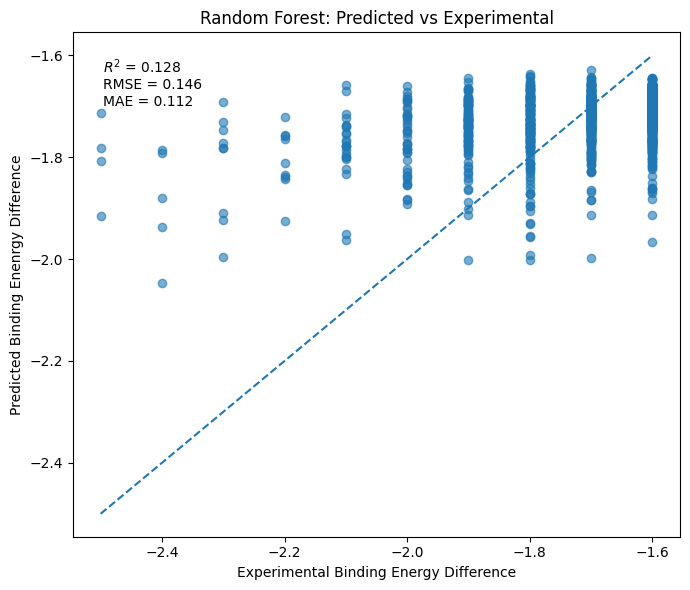

In [31]:
#==================================================================
# PLOTS
# Predicted vs Experimental 
#==================================================================
plt.figure(figsize=(7,6))
plt.scatter(y_test, best_predictions, alpha=0.6)
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Experimental Binding Energy Difference")
plt.ylabel("Predicted Binding Enenrgy Difference")
plt.title(f"{best_model_name}: Predicted vs Experimental")
plt.text(0.05, 0.95, 
         f"$R^2$ = {r2_score(y_test, best_predictions):.3f}\n"
         f"RMSE = {np.sqrt(mean_squared_error(y_test, best_predictions)):.3f}\n"
         f"MAE = {mean_absolute_error(y_test, best_predictions):.3f}",
         transform = plt.gca().transAxes,
         verticalalignment="top")
plt.tight_layout()
plt.savefig("predicted_vs_experimental.png", dpi=300, bbox_inches="tight")
plt.show()

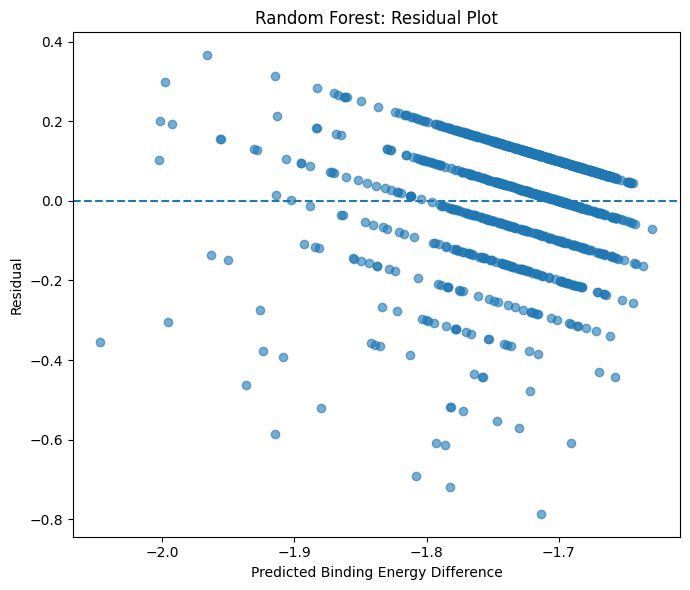

In [32]:
#===============================================================
# Residueal plot
#===============================================================
residuals = y_test.values - best_predictions
plt.figure(figsize=(7, 6))
plt.scatter(best_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Binding Energy Difference")
plt.ylabel("Residual")
plt.title(f"{best_model_name}: Residual Plot")
plt.tight_layout()
plt.savefig("residual_plot.png", dpi=300, bbox_inches="tight")
plt.show()

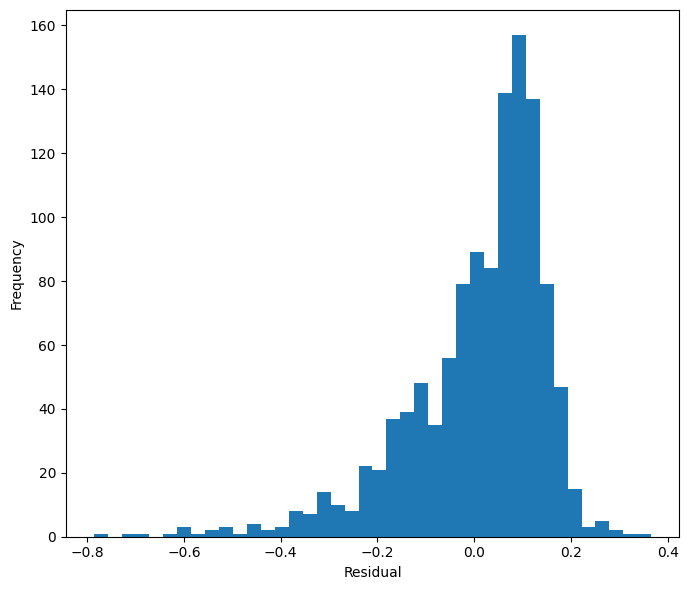

In [33]:
#=======================================================================
# Residual distribution
#=======================================================================
plt.figure(figsize=(7,6))
plt.hist(residuals, bins=40)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("residual_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

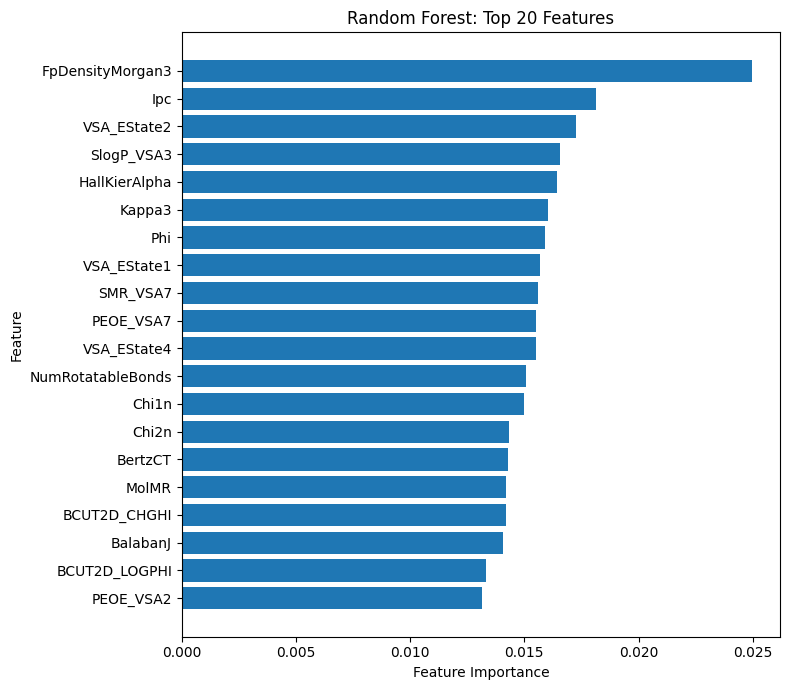

In [34]:
#=========================================================================
# Feature Importance
#=========================================================================

if best_model_name in ["XGBoost", "Random Forest", "CatBoost", "LightGBM"]:
    top_features = (feature_importance_df.head(20).sort_values("Importance"))
    plt.figure(figsize=(8, 7))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"{best_model_name}: Top 20 Features")
    plt.tight_layout()
    plt.savefig("top_20_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()

In [37]:
# SEPARATE TARGET AND FEATURES
X = clean_df.drop(columns=["BindingEnergyDiff", "Scaffold"]).copy()
y = clean_df["BindingEnergyDiff"].copy()

print("\n Number of ML features: ")
print(X.shape[1])

print("\n Featurenames:")
print(X.columns.tolist())

#===================================================================
# 80/20 RANDOM TRAIN-TEST SPLIT 
# Yeo-Johnson Transformation of y values 
#===================================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("\n Training set:")
print(X_train.shape)

print("\n Test set:")
print(X_test.shape)

from sklearn.preprocessing import PowerTransformer
transformer = PowerTransformer(method="yeo-johnson", standardize=True)

y_train_transformed = transformer.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

y_test_transformed = transformer.transform(
    y_test.values.reshape(-1, 1)
).ravel()

#=========================================================
# IMPORTANT:
# X_test / y_test will NOT be used during model selection
#
# Everythin below uses ONLY X_train and y_train


 Number of ML features: 
180

 Featurenames:
['MaxEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan3', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa3', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR_VSA6', 'SMR_VSA7', 'SMR_VSA9', 'SlogP_VSA1', 'SlogP_VSA10', 'SlogP_VSA11', 'SlogP_VSA12', 'SlogP_VSA2', 'SlogP_VSA3', 'SlogP_VSA4', 'SlogP_VSA5', 'SlogP_VSA6', 'SlogP_VSA7', 'SlogP_VSA8', 'TPSA', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'ES

In [44]:
#======================================================================
# EVALUATION FUNCTION
#======================================================================
def evaluate_model_transformed(model, X_data, y_data):
    predictions = model.predict(X_data)

    org_predictions = transformer.inverse_transform(
        predictions.reshape(-1, 1)
    ).ravel()

    r2 = r2_score(y_data, org_predictions)

    rmse = np.sqrt(mean_squared_error(y_data, org_predictions))

    mae = mean_absolute_error(y_data, org_predictions)

    pearson_r, pearson_p = pearsonr(y_data, org_predictions)

    spearman_rho, spearman_p = spearmanr(y_data, org_predictions)

    return {
        "R2" : r2,
        "RMSE" : rmse,
        "MAE" : mae,
        "Pearson_r" : pearson_r,
        "Pearson_p" : pearson_p,
        "Spearman_rho" : spearman_rho,
        "Spearman_p" : spearman_p
    }

In [39]:
results_transformed = {}
best_models_transformed = {}
#================================================================
# RUN ALL MODELS of TRANSFORMED DATA
#=================================================================
for name, search in models.items():
    print("\n")
    print("=" * 80)
    print(f"TRAINING .......... {name}")
    print("=" * 80)

    search.fit(X_train, y_train_transformed)

    best_models_transformed[name] = search.best_estimator_

    results_transformed[name] = {
        "Best CV RMSE" : search.best_score_,
        "Best Parameters" : search.best_params_
    }

    print("\n Best CV RMSE: ")
    print(search.best_score_)

    print("\n Best parameters:")
    print(search.best_params_)



TRAINING .......... XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.2s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.3s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   5.2s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   5.0s
[CV] END colsample_bytree=0.9, learning_rate=0.01, max_depth=3, min_

In [45]:
#====================================================================
# FINAL TEST SET EVALUATION of TRANSFORMED DATA
#====================================================================
test_results_transformed = []

for name, model in best_models_transformed.items():
    print("\n")
    print("=" * 80)
    print(f"FINAL TEST EVALUATION: {name}")
    print("=" * 80)

    metrics = evaluate_model_transformed(model, X_test, y_test_transformed)

    print("\n R2: ")
    print(metrics["R2"])

    print("\n RMSE: ")
    print(metrics["RMSE"])

    print("\n MAE: ")
    print(metrics["MAE"])

    print("\n Pearson r :")
    print(metrics["Pearson_r"])

    print("\n Spearman rho: ")
    print(metrics["Spearman_rho"])

    test_results_transformed.append({
        "Model" : name,
        **metrics
    })



FINAL TEST EVALUATION: XGBoost

 R2: 
-3.0444304157699555

 RMSE: 
1.9558114337535302

 MAE: 
1.7132259432718717

 Pearson r :
0.28977284989508995

 Spearman rho: 
0.2698055091599908


FINAL TEST EVALUATION: SVR-RBF

 R2: 
-3.0460119268745114

 RMSE: 
1.9561937910772231

 MAE: 
1.7134205466905756

 Pearson r :
0.24955627137821898

 Spearman rho: 
0.24546153363313583


FINAL TEST EVALUATION: CatBoost

 R2: 
-3.050913446921154

 RMSE: 
1.9573783428138434

 MAE: 
1.71506480499742

 Pearson r :
0.30660044870886954

 Spearman rho: 
0.28762860865232065


FINAL TEST EVALUATION: LightGBM

 R2: 
-3.0516527299601837

 RMSE: 
1.9575569433459958

 MAE: 
1.7153545366192045

 Pearson r :
0.29390620158471337

 Spearman rho: 
0.27584171540774155


FINAL TEST EVALUATION: Random Forest

 R2: 
-3.0490517656383824

 RMSE: 
1.9569285142210178

 MAE: 
1.7146224152949259

 Pearson r :
0.31475788802560756

 Spearman rho: 
0.2885940453844436


In [46]:
#=================================================================
# RESULTS TABLE of TRANSFORMED DATA
#=================================================================
results_df_transformed = pd.DataFrame(test_results_transformed)

results_df_transfomed = results_df_transformed.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("\n")
print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(results_df_transformed[
    [
        "Model",
        "R2",
        "RMSE",
        "MAE",
        "Pearson_r",
        "Spearman_rho"
    ]
].round(4)
)

#===================================================================
#   SAVE RESULTS
#===================================================================
results_df_transformed.to_csv("ML_model_comparison_transformed.csv", index=False)



FINAL MODEL COMPARISON
           Model      R2    RMSE     MAE  Pearson_r  Spearman_rho
0        XGBoost -3.0444  1.9558  1.7132     0.2898        0.2698
1        SVR-RBF -3.0460  1.9562  1.7134     0.2496        0.2455
2       CatBoost -3.0509  1.9574  1.7151     0.3066        0.2876
3       LightGBM -3.0517  1.9576  1.7154     0.2939        0.2758
4  Random Forest -3.0491  1.9569  1.7146     0.3148        0.2886


In [47]:
#============================================================
# BEST MODEL of TRANSFORMED DATA
#============================================================
best_model_name_transformed = results_df_transformed.iloc[0]["Model"]

best_model_transformed = best_models_transformed[best_model_name_transformed]

print("\n")
print("=" * 80)
print("BEST MODEL")
print("=" * 80)

print(best_model_name_transformed)

print("\n Test RMSE: ")
print(
    results_df_transformed.iloc[0]["RMSE"]
)

print("\n Test R2: ")
print(results_df_transformed.iloc[0]["R2"])

#========================================================================
#    SAVE BEST MODEL
#========================================================================

joblib.dump(
    best_model_transformed,
    f"best_model_{best_model_name_transformed.replace(' ', '_')}.pkl"
)

print("\n Best model saved.")



BEST MODEL
XGBoost

 Test RMSE: 
1.9558114337535302

 Test R2: 
-3.0444304157699555

 Best model saved.


In [48]:
#================================================================
# PREDICTIONS FOR TEST SET of TRANSFORMED DATA
#================================================================

best_predictions_transformed = best_model_transformed.predict(X_test)

org_best_predictions_transformed = transformer.inverse_transform(
    best_predictions_transformed.reshape(-1, 1)
).ravel()

prediction_df_transformed = pd.DataFrame({
    "Experimental" : y_test.values,
    "Predicted" : org_best_predictions_transformed
})

prediction_df_transformed["Residual"] = ( 
    prediction_df_transformed["Experimental"] - prediction_df_transformed["Predicted"]
    )

prediction_df_transformed.to_csv(
    "best_model_test_predictions_transformed.csv",
    index=False
)